In [ ]:
# Install PySpark
!pip install -q pyspark


In [ ]:

# Import SparkSession
from pyspark.sql import SparkSession

# Start Apache Spark
spark = SparkSession.builder \
    .appName("Sentiment140Analysis") \
    .master("local[*]") \
    .getOrCreate()

print("Spark started successfully!")
print("Spark version:", spark.version)


Spark started successfully!
Spark version: 4.0.4


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving training.1600000.processed.noemoticon.csv to training.1600000.processed.noemoticon.csv


In [ ]:
import os

# Get the uploaded filename
file_name = list(uploaded.keys())[0]
file_path = "/content/" + file_name

# Display file details
print("File name:", file_name)
print("File size (MB):", round(
    os.path.getsize(file_path) / (1024 * 1024), 2
))

File name: training.1600000.processed.noemoticon.csv
File size (MB): 227.74


In [ ]:
import csv
from collections import Counter

labels = Counter()
total_rows = 0
bad_rows = 0

with open(file_path, "r", encoding="latin-1", newline="") as f:
    reader = csv.reader(f)

    for row in reader:
        total_rows += 1

        if len(row) != 6:
            bad_rows += 1
        elif row[0].strip() in ("0", "4"):
            labels[row[0].strip()] += 1
        else:
            bad_rows += 1

print("Total records:", total_rows)
print("Negative tweets (0):", labels["0"])
print("Positive tweets (4):", labels["4"])
print("Malformed records:", bad_rows)

Total records: 1600000
Negative tweets (0): 800000
Positive tweets (4): 800000
Malformed records: 0


In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Sentiment140Analysis") \
    .master("local[*]") \
    .getOrCreate()

print("Spark version:", spark.version)
print("Spark session is ready!")

Spark version: 4.0.4
Spark session is ready!


In [ ]:
from pyspark.sql.types import (
    StructType, StructField, IntegerType, StringType
)

# Define the dataset columns and their data types
schema = StructType([
    StructField("sentiment", IntegerType(), True),
    StructField("tweet_id", StringType(), True),
    StructField("date", StringType(), True),
    StructField("query", StringType(), True),
    StructField("user", StringType(), True),
    StructField("text", StringType(), True)
])

# Load the CSV file into Spark
df = spark.read.csv(
    file_path,
    schema=schema,
    header=False,
    encoding="UTF-8"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
# Display the first 5 tweets
df.show(5, truncate=False)

# Display the number of rows and columns
print("Total rows:", df.count())
print("Total columns:", len(df.columns))

# Display column names and data types
df.printSchema()

+---------+----------+----------------------------+--------+---------------+-------------------------------------------------------------------------------------------------------------------+
|sentiment|tweet_id  |date                        |query   |user           |text                                                                                                               |
+---------+----------+----------------------------+--------+---------------+-------------------------------------------------------------------------------------------------------------------+
|0        |1467810369|Mon Apr 06 22:19:45 PDT 2009|NO_QUERY|_TheSpecialOne_|@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer.  You shoulda got David Carr of Third Day to do it. ;D|
|0        |1467810672|Mon Apr 06 22:19:49 PDT 2009|NO_QUERY|scotthamilton  |is upset that he can't update his Facebook by texting it... and might cry as a result  School today also. Blah!    |
|0        |1467810917|Mon Apr 06 22

In [ ]:
from pyspark.sql.functions import when, col

df = df.withColumn(
    "sentiment_label",
    when(col("sentiment") == 0, "Negative")
    .when(col("sentiment") == 4, "Positive")
)

# Display tweet text with its sentiment
df.select("text", "sentiment", "sentiment_label").show(
    10, truncate=False
)

+-------------------------------------------------------------------------------------------------------------------+---------+---------------+
|text                                                                                                               |sentiment|sentiment_label|
+-------------------------------------------------------------------------------------------------------------------+---------+---------------+
|@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer.  You shoulda got David Carr of Third Day to do it. ;D|0        |Negative       |
|is upset that he can't update his Facebook by texting it... and might cry as a result  School today also. Blah!    |0        |Negative       |
|@Kenichan I dived many times for the ball. Managed to save 50%  The rest go out of bounds                          |0        |Negative       |
|my whole body feels itchy and like its on fire                                                                     |0        |Negative 

In [ ]:
from pyspark.sql.functions import count, col

# Count tweets in each sentiment category
df.groupBy("sentiment_label") \
    .agg(count("*").alias("total_tweets")) \
    .show()



+---------------+------------+
|sentiment_label|total_tweets|
+---------------+------------+
|       Positive|      800000|
|       Negative|      800000|
+---------------+------------+



In [ ]:
from pyspark.sql.functions import sum, when, trim

# Count missing values in each column
df.select([
    sum(
        when(col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in df.columns
]).show()

+---------+--------+----+-----+----+----+---------------+
|sentiment|tweet_id|date|query|user|text|sentiment_label|
+---------+--------+----+-----+----+----+---------------+
|        0|       0|   0|    0|   0|   0|              0|
+---------+--------+----+-----+----+----+---------------+



In [ ]:
empty_tweets = df.filter(
    col("text").isNull() | (trim(col("text")) == "")
).count()

print("Tweets with empty text:", empty_tweets)

Tweets with empty text: 0


In [ ]:
# Count duplicate tweet IDs
duplicate_ids = (
    df.groupBy("tweet_id")
      .count()
      .filter(col("count") > 1)
      .count()
)

print("Tweet IDs occurring more than once:", duplicate_ids)


Tweet IDs occurring more than once: 1685


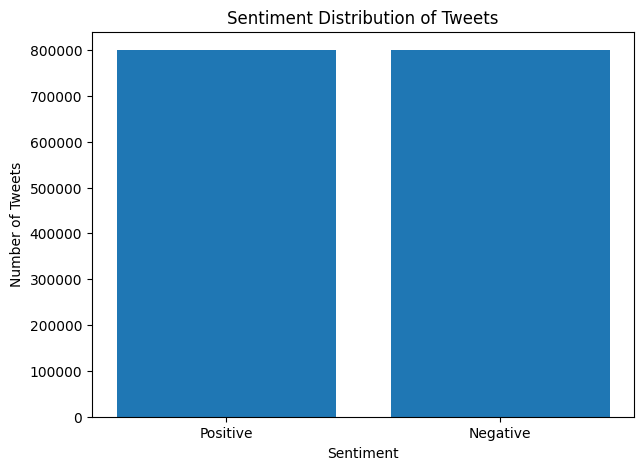

In [ ]:
import matplotlib.pyplot as plt

sentiment_counts = (
    df.groupBy("sentiment_label")
      .count()
      .collect()
)

labels = [row["sentiment_label"] for row in sentiment_counts]
counts = [row["count"] for row in sentiment_counts]

plt.figure(figsize=(7, 5))
plt.bar(labels, counts)
plt.title("Sentiment Distribution of Tweets")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.show()

In [ ]:
from pyspark.sql.functions import (
    lower, regexp_replace, trim, col
)

# Remove rows where tweet text is missing or empty
df_clean = df.filter(
    col("text").isNotNull() & (trim(col("text")) != "")
)

# Convert text to lowercase
df_clean = df_clean.withColumn(
    "clean_text",
    lower(col("text"))
)

# Remove URLs
df_clean = df_clean.withColumn(
    "clean_text",
    regexp_replace(col("clean_text"), r"https?://\S+|www\.\S+", "")
)

# Remove usernames such as @john
df_clean = df_clean.withColumn(
    "clean_text",
    regexp_replace(col("clean_text"), r"@\w+", "")
)

# Remove punctuation and special characters
df_clean = df_clean.withColumn(
    "clean_text",
    regexp_replace(col("clean_text"), r"[^a-zA-Z\s]", " ")
)

# Remove extra spaces
df_clean = df_clean.withColumn(
    "clean_text",
    trim(regexp_replace(col("clean_text"), r"\s+", " "))
)

# Remove tweets that become empty after cleaning
df_clean = df_clean.filter(col("clean_text") != "")

# Show original and cleaned text
df_clean.select(
    "text", "clean_text", "sentiment_label"
).show(10, truncate=False)

print("Tweets remaining after cleaning:", df_clean.count())

+-------------------------------------------------------------------------------------------------------------------+---------------------------------------------------------------------------------------------------------+---------------+
|text                                                                                                               |clean_text                                                                                               |sentiment_label|
+-------------------------------------------------------------------------------------------------------------------+---------------------------------------------------------------------------------------------------------+---------------+
|@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer.  You shoulda got David Carr of Third Day to do it. ;D|awww that s a bummer you shoulda got david carr of third day to do it d                                  |Negative       |
|is upset that he can't update his Faceb

In [ ]:
from pyspark.sql.functions import when, col

df_ml = df_clean.withColumn(
    "label",
    when(col("sentiment") == 0, 0.0)
    .when(col("sentiment") == 4, 1.0)
)

# Keep only the columns required for machine learning
df_ml = df_ml.select("clean_text", "label")

# Remove rows with missing labels or text
df_ml = df_ml.filter(
    col("clean_text").isNotNull() &
    (col("clean_text") != "") &
    col("label").isNotNull()
)

df_ml.show(5, truncate=False)
print("Rows available for ML:", df_ml.count())

+---------------------------------------------------------------------------------------------------------+-----+
|clean_text                                                                                               |label|
+---------------------------------------------------------------------------------------------------------+-----+
|awww that s a bummer you shoulda got david carr of third day to do it d                                  |0.0  |
|is upset that he can t update his facebook by texting it and might cry as a result school today also blah|0.0  |
|i dived many times for the ball managed to save the rest go out of bounds                                |0.0  |
|my whole body feels itchy and like its on fire                                                           |0.0  |
|no it s not behaving at all i m mad why am i here because i can t see you all over there                 |0.0  |
+---------------------------------------------------------------------------------------

In [ ]:
train_df, test_df = df_ml.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

Training rows: 1277513
Testing rows: 318790


In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Tokenizer, HashingTF
from pyspark.ml.classification import LogisticRegression

# Split cleaned tweets into words
tokenizer = Tokenizer(
    inputCol="clean_text",
    outputCol="words"
)

# Convert words into numerical features
hashing_tf = HashingTF(
    inputCol="words",
    outputCol="features",
    numFeatures=10000
)

# Create the classification model
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=10
)

# Combine all steps into one pipeline
pipeline = Pipeline(
    stages=[tokenizer, hashing_tf, lr]
)

print("ML pipeline created successfully!")

ML pipeline created successfully!


In [ ]:
model = pipeline.fit(train_df)

print("Model training completed!")


Model training completed!


In [ ]:
predictions = model.transform(test_df)

predictions.select(
    "clean_text",
    "label",
    "prediction",
    "probability"
).show(10, truncate=False)


+----------------------------------------------------------------------------------------------------------------------+-----+----------+-----------------------------------------+
|clean_text                                                                                                            |label|prediction|probability                              |
+----------------------------------------------------------------------------------------------------------------------+-----+----------+-----------------------------------------+
|a                                                                                                                     |0.0  |1.0       |[0.3869693581240347,0.6130306418759652]  |
|a airfranceflight                                                                                                     |0.0  |1.0       |[0.3223276737132719,0.6776723262867281]  |
|a all the fairy dust                                                                               

In [ ]:
from pyspark.ml.evaluation import (
    MulticlassClassificationEvaluator,
    BinaryClassificationEvaluator
)

# Accuracy
accuracy_eval = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

# Precision
precision_eval = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedPrecision"
)

# Recall
recall_eval = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedRecall"
)

# F1-score
f1_eval = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

# ROC-AUC
auc_eval = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

print("Accuracy:", round(accuracy_eval.evaluate(predictions), 4))
print("Weighted Precision:", round(precision_eval.evaluate(predictions), 4))
print("Weighted Recall:", round(recall_eval.evaluate(predictions), 4))
print("F1-score:", round(f1_eval.evaluate(predictions), 4))
print("ROC-AUC:", round(auc_eval.evaluate(predictions), 4))

Accuracy: 0.7794
Weighted Precision: 0.7797
Weighted Recall: 0.7794
F1-score: 0.7794
ROC-AUC: 0.8516


In [ ]:
# Sample tweets to test our trained model
sample_tweets = [
    "I absolutely love this phone, the camera is amazing!",
    "This is the worst product I have ever purchased.",
    "The service was excellent and the staff were very helpful.",
    "I am really disappointed with this terrible experience.",
    "What a wonderful day, I am feeling great!"
]

# Create a Spark DataFrame
new_tweets = spark.createDataFrame(
    [(tweet,) for tweet in sample_tweets],
    ["text"]
)

# Apply the same text-cleaning steps used for training
from pyspark.sql.functions import lower, regexp_replace, trim, col

new_tweets = new_tweets.withColumn(
    "clean_text",
    lower(col("text"))
)

new_tweets = new_tweets.withColumn(
    "clean_text",
    regexp_replace(
        col("clean_text"),
        r"https?://\S+|www\.\S+",
        ""
    )
)

new_tweets = new_tweets.withColumn(
    "clean_text",
    regexp_replace(col("clean_text"), r"@\w+", "")
)

new_tweets = new_tweets.withColumn(
    "clean_text",
    regexp_replace(col("clean_text"), r"[^a-zA-Z\s]", " ")
)

new_tweets = new_tweets.withColumn(
    "clean_text",
    trim(regexp_replace(col("clean_text"), r"\s+", " "))
)

# Predict sentiment using our trained model
live_predictions = model.transform(new_tweets)

# Convert numeric predictions to readable labels
live_predictions = live_predictions.withColumn(
    "predicted_sentiment",
    when(col("prediction") == 0.0, "Negative")
    .otherwise("Positive")
)

live_predictions.select(
    "text",
    "predicted_sentiment"
).show(truncate=False)

+----------------------------------------------------------+-------------------+
|text                                                      |predicted_sentiment|
+----------------------------------------------------------+-------------------+
|I absolutely love this phone, the camera is amazing!      |Positive           |
|This is the worst product I have ever purchased.          |Negative           |
|The service was excellent and the staff were very helpful.|Positive           |
|I am really disappointed with this terrible experience.   |Negative           |
|What a wonderful day, I am feeling great!                 |Positive           |
+----------------------------------------------------------+-------------------+



In [ ]:
# Sample social media posts for our simulated stream

stream_tweets = [
    "This new phone is amazing and the camera is fantastic!",
    "Very disappointed with the quality of this product.",
    "I love the customer service, they were so helpful.",
    "Worst shopping experience ever, never buying again.",
    "Really happy with my purchase today!",
    "The battery life is terrible and very frustrating.",
    "Excellent product, totally worth the money.",
    "I hate waiting so long for customer support.",
    "The new update works perfectly, great job!",
    "Poor quality and a complete waste of money.",
    "I am enjoying this product so much.",
    "The delivery was late and the package was damaged.",
    "Fantastic experience, I would recommend it!",
    "This product is disappointing and unreliable.",
    "Everything worked well, very satisfied!"
]

# Divide tweets into batches of 5
batch_size = 5

batches = [
    stream_tweets[i:i + batch_size]
    for i in range(0, len(stream_tweets), batch_size)
]

print("Total simulated tweets:", len(stream_tweets))
print("Number of batches:", len(batches))
print("Tweets per batch:", batch_size)


Total simulated tweets: 15
Number of batches: 3
Tweets per batch: 5


In [ ]:
from pyspark.sql.functions import (
    lower, regexp_replace, trim, col, when
)

# Store predictions from every batch
all_batch_results = []

for batch_number, batch in enumerate(batches, start=1):

    print(f"\nProcessing Batch {batch_number}")

    # Convert incoming tweets to a Spark DataFrame
    batch_df = spark.createDataFrame(
        [(tweet,) for tweet in batch],
        ["text"]
    )

    # Clean the incoming text
    batch_df = batch_df.withColumn(
        "clean_text",
        lower(col("text"))
    )

    batch_df = batch_df.withColumn(
        "clean_text",
        regexp_replace(
            col("clean_text"),
            r"https?://\S+|www\.\S+",
            ""
        )
    )

    batch_df = batch_df.withColumn(
        "clean_text",
        regexp_replace(col("clean_text"), r"@\w+", "")
    )

    batch_df = batch_df.withColumn(
        "clean_text",
        regexp_replace(
            col("clean_text"),
            r"[^a-zA-Z\s]",
            " "
        )
    )

    batch_df = batch_df.withColumn(
        "clean_text",
        trim(regexp_replace(col("clean_text"), r"\s+", " "))
    )

    # Predict sentiment
    predictions_batch = model.transform(batch_df)

    predictions_batch = predictions_batch.withColumn(
        "predicted_sentiment",
        when(col("prediction") == 0.0, "Negative")
        .otherwise("Positive")
    )

    # Display the results for this batch
    predictions_batch.select(
        "text", "predicted_sentiment"
    ).show(truncate=False)

    # Save this batch's predictions for combined analysis
    all_batch_results.append(
        predictions_batch.select("text", "predicted_sentiment")
    )

print("All batches processed successfully!")


Processing Batch 1
+------------------------------------------------------+-------------------+
|text                                                  |predicted_sentiment|
+------------------------------------------------------+-------------------+
|This new phone is amazing and the camera is fantastic!|Positive           |
|Very disappointed with the quality of this product.   |Negative           |
|I love the customer service, they were so helpful.    |Positive           |
|Worst shopping experience ever, never buying again.   |Negative           |
|Really happy with my purchase today!                  |Positive           |
+------------------------------------------------------+-------------------+


Processing Batch 2
+--------------------------------------------------+-------------------+
|text                                              |predicted_sentiment|
+--------------------------------------------------+-------------------+
|The battery life is terrible and very frustrat

In [ ]:
from functools import reduce

# Combine all batch results into one DataFrame
stream_results = reduce(
    lambda df1, df2: df1.unionByName(df2),
    all_batch_results
)

# Count positive and negative predictions
stream_results.groupBy("predicted_sentiment") \
    .count() \
    .show()

# Calculate total tweets processed
total_processed = stream_results.count()

# Count each sentiment category
positive_count = stream_results.filter(
    col("predicted_sentiment") == "Positive"
).count()

negative_count = stream_results.filter(
    col("predicted_sentiment") == "Negative"
).count()

print("Total tweets processed:", total_processed)
print("Positive tweets:", positive_count)
print("Negative tweets:", negative_count)

print(
    "Positive percentage:",
    round(positive_count / total_processed * 100, 2), "%"
)

print(
    "Negative percentage:",
    round(negative_count / total_processed * 100, 2), "%"
)

+-------------------+-----+
|predicted_sentiment|count|
+-------------------+-----+
|           Positive|    8|
|           Negative|    7|
+-------------------+-----+

Total tweets processed: 15
Positive tweets: 8
Negative tweets: 7
Positive percentage: 53.33 %
Negative percentage: 46.67 %


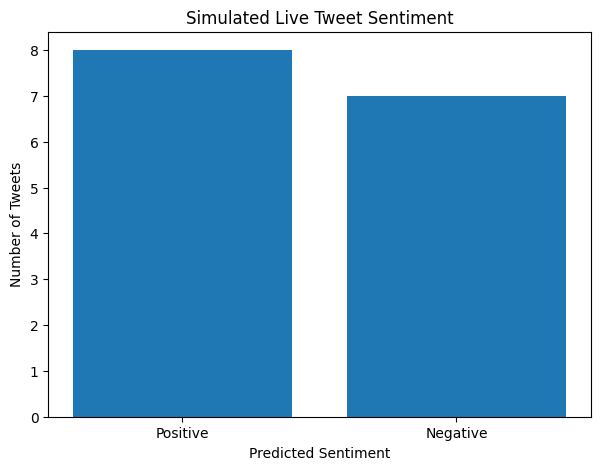

In [ ]:
import matplotlib.pyplot as plt

sentiment_summary = (
    stream_results.groupBy("predicted_sentiment")
    .count()
    .collect()
)

labels = [row["predicted_sentiment"] for row in sentiment_summary]
counts = [row["count"] for row in sentiment_summary]

plt.figure(figsize=(7, 5))
plt.bar(labels, counts)
plt.title("Simulated Live Tweet Sentiment")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Number of Tweets")
plt.show()



In [ ]:
%pip install -q plotly

In [ ]:
import pandas as pd
import plotly.express as px
from pyspark.sql.functions import col

# Collect the small simulated stream for dashboard display
dashboard_df = stream_results.toPandas()

# Calculate statistics
total_tweets = len(dashboard_df)

positive_count = (
    dashboard_df["predicted_sentiment"] == "Positive"
).sum()

negative_count = (
    dashboard_df["predicted_sentiment"] == "Negative"
).sum()

positive_percent = positive_count / total_tweets * 100
negative_percent = negative_count / total_tweets * 100

print("Dashboard data prepared!")
print("Total tweets:", total_tweets)
print("Positive:", positive_count)
print("Negative:", negative_count)

Dashboard data prepared!
Total tweets: 15
Positive: 8
Negative: 7


In [ ]:
from IPython.display import display, HTML

display(HTML(f"""
<div style="display:flex; flex-wrap:wrap; gap:15px; font-family:Arial;">
  <div style="flex:1; min-width:150px; background:#1f2937;
              color:white; padding:20px; border-radius:12px;">
    <div style="font-size:14px;">Total Tweets</div>
    <div style="font-size:32px; font-weight:bold;">{total_tweets}</div>
  </div>

  <div style="flex:1; min-width:150px; background:#166534;
              color:white; padding:20px; border-radius:12px;">
    <div style="font-size:14px;">Positive Tweets</div>
    <div style="font-size:32px; font-weight:bold;">{positive_count}</div>
    <div>{positive_percent:.2f}%</div>
  </div>

  <div style="flex:1; min-width:150px; background:#991b1b;
              color:white; padding:20px; border-radius:12px;">
    <div style="font-size:14px;">Negative Tweets</div>
    <div style="font-size:32px; font-weight:bold;">{negative_count}</div>
    <div>{negative_percent:.2f}%</div>
  </div>
</div>
"""))

In [ ]:
summary_df = pd.DataFrame({
    "Sentiment": ["Positive", "Negative"],
    "Count": [positive_count, negative_count]
})

fig = px.pie(
    summary_df,
    names="Sentiment",
    values="Count",
    title="Sentiment Distribution of Simulated Tweets",
    hole=0.45,
    color="Sentiment",
    color_discrete_map={
        "Positive": "#16A34A",
        "Negative": "#DC2626"
    }
)

fig.update_traces(textinfo="label+percent+value")
fig.show()

In [ ]:
recent_tweets = dashboard_df.tail(10).copy()

display(
    recent_tweets[
        ["text", "predicted_sentiment"]
    ].reset_index(drop=True)
)

,text,predicted_sentiment
0,The battery life is terrible and very frustrat...,Negative
1,"Excellent product, totally worth the money.",Positive
2,I hate waiting so long for customer support.,Negative
3,"The new update works perfectly, great job!",Positive
4,Poor quality and a complete waste of money.,Negative
5,I am enjoying this product so much.,Positive
6,The delivery was late and the package was dama...,Negative
7,"Fantastic experience, I would recommend it!",Positive
8,This product is disappointing and unreliable.,Negative
9,"Everything worked well, very satisfied!",Positive


In [ ]:
fig = px.bar(
    summary_df,
    x="Sentiment",
    y="Count",
    color="Sentiment",
    title="Positive vs Negative Tweets",
    text="Count",
    color_discrete_map={
        "Positive": "#16A34A",
        "Negative": "#DC2626"
    }
)

fig.update_layout(
    xaxis_title="Predicted Sentiment",
    yaxis_title="Number of Tweets",
    showlegend=False
)

fig.show()

In [ ]:
# Save the trained pipeline
model_path = "/content/sentiment_model"

model.write().overwrite().save(model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: /content/sentiment_model


In [ ]:
# Convert the simulated stream results to a CSV file
csv_path = "/content/simulated_sentiment_results.csv"

dashboard_df.to_csv(csv_path, index=False)

print("Predictions exported successfully!")
print("File:", csv_path)

Predictions exported successfully!
File: /content/simulated_sentiment_results.csv


In [ ]:
metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Score": [
        0.7794,
        0.7797,
        0.7794,
        0.7794,
        0.8516
    ]
})

metrics.to_csv("/content/model_evaluation_metrics.csv", index=False)

display(metrics)
print("Evaluation metrics exported!")

,Metric,Score
0,Accuracy,0.7794
1,Weighted Precision,0.7797
2,Weighted Recall,0.7794
3,F1-score,0.7794
4,ROC-AUC,0.8516


Evaluation metrics exported!


In [ ]:
from google.colab import files

files.download("/content/simulated_sentiment_results.csv")
files.download("/content/model_evaluation_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil

shutil.make_archive(
    "/content/sentiment_model",
    "zip",
    "/content/sentiment_model"
)

files.download("/content/sentiment_model.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Step 1: Check the Spark and PySpark versions
import pyspark
print("PySpark version:", pyspark.__version__)
print("Spark version:", spark.version)

# Step 2: Save the trained ML pipeline
model_path = "/content/sentiment_model"

model.write().overwrite().save(model_path)

print("Model saved successfully!")

# Step 3: Compress the model folder into a ZIP file
import shutil

zip_path = shutil.make_archive(
    "/content/sentiment_model",
    "zip",
    model_path
)

print("ZIP file created:", zip_path)


PySpark version: 4.0.4
Spark version: 4.0.4
Model saved successfully!
ZIP file created: /content/sentiment_model.zip


In [ ]:
from google.colab import files
files.download("/content/sentiment_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%pip install -q gradio plotly

In [ ]:
print("Spark version:", spark.version)
print("Model loaded:", model is not None)
print("Model stages:", len(model.stages))

Spark version: 4.0.4
Model loaded: True
Model stages: 3


In [ ]:

# ============================================
# SOCIAL MEDIA SENTIMENT ANALYSIS DASHBOARD
# Gradio + Apache Spark MLlib
# ============================================

%pip install -q gradio plotly

import re
import pandas as pd
import gradio as gr
import plotly.express as px

from pyspark.sql.functions import (
    col, lower, regexp_replace, trim
)

# --------------------------------------------
# 1. CHECK THE EXISTING MODEL
# --------------------------------------------

print("Spark version:", spark.version)
print("Pipeline stages:", len(model.stages))
print("Model is ready!")


# --------------------------------------------
# 2. TEXT CLEANING
# Use the same basic preprocessing as training
# --------------------------------------------

def clean_tweet(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


# --------------------------------------------
# 3. SINGLE TWEET PREDICTION
# --------------------------------------------

def analyze_tweet(tweet):
    if not tweet or not tweet.strip():
        return "Please enter a tweet.", ""

    cleaned = clean_tweet(tweet)

    if not cleaned:
        return "No usable text found.", ""

    input_df = spark.createDataFrame(
        [(cleaned,)], ["clean_text"]
    )

    result = model.transform(input_df).first()

    if result["prediction"] == 1.0:
        sentiment = "Positive 😊"
        explanation = (
            "The model classifies this tweet as positive."
        )
    else:
        sentiment = "Negative ☹️"
        explanation = (
            "The model classifies this tweet as negative."
        )

    return sentiment, explanation


# --------------------------------------------
# 4. BATCH TWEET ANALYSIS
# Enter one tweet per line
# --------------------------------------------

def analyze_batch(text):
    if not text or not text.strip():
        return (
            pd.DataFrame(columns=["Tweet", "Sentiment"]),
            None,
            "Please enter at least one tweet."
        )

    tweets = [
        line.strip()
        for line in text.splitlines()
        if line.strip()
    ]

    if not tweets:
        return (
            pd.DataFrame(columns=["Tweet", "Sentiment"]),
            None,
            "No tweets were provided."
        )

    cleaned_tweets = [clean_tweet(t) for t in tweets]

    valid_rows = [
        (original, cleaned)
        for original, cleaned in zip(tweets, cleaned_tweets)
        if cleaned
    ]

    if not valid_rows:
        return (
            pd.DataFrame(columns=["Tweet", "Sentiment"]),
            None,
            "No usable tweet text was found."
        )

    input_df = spark.createDataFrame(
        [(original, cleaned) for original, cleaned in valid_rows],
        ["text", "clean_text"]
    )

    predictions = model.transform(input_df)

    results = predictions.select(
        "text", "prediction"
    ).collect()

    records = []

    for row in results:
        label = (
            "Positive"
            if row["prediction"] == 1.0
            else "Negative"
        )

        records.append({
            "Tweet": row["text"],
            "Sentiment": label
        })

    results_df = pd.DataFrame(records)

    counts = (
        results_df["Sentiment"]
        .value_counts()
        .reindex(["Positive", "Negative"], fill_value=0)
    )

    total = len(results_df)
    positive = int(counts["Positive"])
    negative = int(counts["Negative"])

    summary = (
        f"### Batch Summary\n"
        f"- **Tweets analyzed:** {total}\n"
        f"- **Positive:** {positive} "
        f"({positive / total * 100:.2f}%)\n"
        f"- **Negative:** {negative} "
        f"({negative / total * 100:.2f}%)"
    )

    chart_df = pd.DataFrame({
        "Sentiment": ["Positive", "Negative"],
        "Count": [positive, negative]
    })

    fig = px.pie(
        chart_df,
        names="Sentiment",
        values="Count",
        title="Sentiment Distribution",
        color="Sentiment",
        color_discrete_map={
            "Positive": "#16A34A",
            "Negative": "#DC2626"
        },
        hole=0.4
    )

    return results_df, fig, summary


# --------------------------------------------
# 5. MODEL PERFORMANCE
# Actual results from your Colab evaluation
# --------------------------------------------

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Score": [
        "77.94%",
        "77.97%",
        "77.94%",
        "77.94%",
        "85.16%"
    ]
})


# --------------------------------------------
# 6. BUILD THE GRADIO INTERFACE
# --------------------------------------------

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Social Media Sentiment Analytics"
) as demo:

    gr.Markdown(
        """
        # Social Media Sentiment Analytics
        ### Powered by Apache Spark MLlib and Logistic Regression

        Analyze tweet sentiment, explore batch results,
        and review model evaluation metrics.
        """
    )

    with gr.Tab("Tweet Analyzer"):

        tweet_input = gr.Textbox(
            label="Enter a tweet",
            placeholder="I absolutely love this product!",
            lines=4
        )

        analyze_button = gr.Button(
            "Analyze Sentiment",
            variant="primary"
        )

        sentiment_output = gr.Textbox(
            label="Predicted Sentiment"
        )

        explanation_output = gr.Textbox(
            label="Result"
        )

        analyze_button.click(
            fn=analyze_tweet,
            inputs=tweet_input,
            outputs=[
                sentiment_output,
                explanation_output
            ]
        )

        gr.Examples(
            examples=[
                ["I absolutely love this product!"],
                ["This is the worst purchase ever."],
                ["The service was excellent and helpful."],
                ["I am disappointed with the quality."]
            ],
            inputs=tweet_input
        )

    with gr.Tab("Batch Analysis"):

        batch_input = gr.Textbox(
            label="Enter multiple tweets (one per line)",
            placeholder=(
                "Amazing product!\n"
                "Terrible service.\n"
                "I am very happy today."
            ),
            lines=8
        )

        batch_button = gr.Button(
            "Analyze Batch",
            variant="primary"
        )

        batch_summary = gr.Markdown()

        batch_table = gr.Dataframe(
            label="Tweet Predictions",
            interactive=False
        )

        batch_chart = gr.Plot(
            label="Sentiment Chart"
        )

        batch_button.click(
            fn=analyze_batch,
            inputs=batch_input,
            outputs=[
                batch_table,
                batch_chart,
                batch_summary
            ]
        )

    with gr.Tab("Model Performance"):

        gr.Markdown(
            """
            ## Evaluation on the held-out test dataset

            These metrics were obtained during the original
            model evaluation in Google Colab.
            """
        )

        gr.Dataframe(
            value=metrics_df,
            label="Model Evaluation Metrics",
            interactive=False
        )

        gr.Markdown(
            """
            **ROC-AUC: 85.16%** measures the model's ability
            to distinguish between the two sentiment classes.

            **Note:** Evaluation metrics describe performance
            on the held-out dataset, not on every new tweet.
            """
        )

    gr.Markdown(
        """
        ---
        **Project:** Real-Time Social Media Sentiment Analysis
        Using Apache Spark

        **Data source:** Sentiment140 historical dataset

        **Scope:** User-entered tweets and simulated batches.
        This interface does not fetch live posts from Twitter/X.
        """
    )


# --------------------------------------------
# 7. LAUNCH THE DASHBOARD
# --------------------------------------------

demo.launch(share=True)





Spark version: 4.0.4
Pipeline stages: 3
Model is ready!


/tmp/ipykernel_1381/3082009595.py:208: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.



Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d5e5e244be470eeb30.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
